# Modeling and Evaluation

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

In [9]:
df = pd.read_csv("data/processed_data.csv")

## Splitting the Data

First, we split the data into player codes, features X, and labels y. Player codes are needed to group by player in the splitting process.

In [10]:
player_codes = df["code"]
y = df["POS"]
X = df.drop(["POS", "code"], axis=1)

Now let's split the data further into an 80 % training set and a 20 % test set.

This method keeps the class proportions the same as in the original dataset and groups by player so the same player's different seasons do not end up on both the training and the test set.

In [11]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
train_idx, test_idx = next(sgkf.split(X, y, groups=player_codes))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
codes_train, codes_test = player_codes.iloc[train_idx], player_codes.iloc[test_idx]

In [12]:
# defines which split strategy the 5-fold cross-validations are going to use later on
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)

## Training

As classifiers we use random forest and multinomial logistic regression. In both cases, model training and parameter tuning uses 5-fold cross-validation on the training set. First, we perform a wide search to find the general ballpark of the parameters, then a narrower search centered on that region to find the best values more precisely.

Macro-averaged F1 score is used as the evaluation metric since the dataset is imbalanced with equally important classes. Both classifiers also use balanced class weights for the same reason.

### Random Forest

In [ ]:
# which parameters to try
param_grid = {"max_depth": [3, 4, 5, 6, 7, 8, 10, None], "n_estimators": [100, 200, 300, 400, 500]}

forest = RandomForestClassifier(class_weight="balanced", random_state=1)

# GridSearchCV performs the cross-validation and trains the model
rf_grid = GridSearchCV(forest, param_grid=param_grid, cv=cv, scoring="f1_macro")
rf_grid.fit(X_train, y_train, groups=codes_train)

print("best RF params: ", rf_grid.best_params_, "\nbest macro F1: ", rf_grid.best_score_)

best RF params:  {'max_depth': 3, 'n_estimators': 300} 
best macro F1:  0.786774272566816


Now let's narrow down the parameters.

In [7]:
param_grid = {"max_depth": [1, 2, 3, 4], "n_estimators": [250, 275, 300, 325, 350, 375]}

# overwrite the earlier model
rf_grid = GridSearchCV(forest, param_grid=param_grid, cv=cv, scoring="f1_macro")
rf_grid.fit(X_train, y_train, groups=codes_train)

print("best RF params: ", rf_grid.best_params_, "\nbest macro F1: ", rf_grid.best_score_)

best RF params:  {'max_depth': 3, 'n_estimators': 300} 
best macro F1:  0.786774272566816


In [8]:
rf_model = rf_grid.best_estimator_ # Save the trained model as rf_model

With params figured out and the model trained (GridSearchCV trains the model as well), we move on and train the multinomial logistic regression model.

### Multinomial Logistic Regression

Logistic regression requires standardized features. We use Pipeline to standardize the data in each CV fold separately based on only the training set's values, so that none of the scaling depends on the validation set's values.

In [9]:
lr_pipe = Pipeline([('scaler', StandardScaler()), 
                    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=1))])

lr_param_grid = {"clf__C": [0.01, 0.1, 1, 10, 100]}
lr_grid = GridSearchCV(lr_pipe, param_grid=lr_param_grid, cv=cv, scoring="f1_macro")
lr_grid.fit(X_train, y_train, groups=codes_train)

print("best LR params: ", lr_grid.best_params_)
print("best LR macro F1: ", lr_grid.best_score_)

best LR params:  {'clf__C': 0.01}
best LR macro F1:  0.7917975232533492


Narrow down the parameters

In [10]:
lr_pipe = Pipeline([('scaler', StandardScaler()), 
                    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=1))])

lr_param_grid = {"clf__C": [0.001, 0.003, 0.005, 0.007, 0.01, 0.02, 0.03, 0.05]}
lr_grid = GridSearchCV(lr_pipe, param_grid=lr_param_grid, cv=cv, scoring="f1_macro")
lr_grid.fit(X_train, y_train, groups=codes_train)

print("best LR params: ", lr_grid.best_params_)
print("best LR macro F1: ", lr_grid.best_score_)

best LR params:  {'clf__C': 0.01}
best LR macro F1:  0.7917975232533492


In [11]:
# Save the trained logistic regression model as lr_model
lr_model = lr_grid.best_estimator_

## Evaluation

With parameters figured out, we evaluate the models' performance on the test set.

In [12]:
y_pred_rf = rf_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)

### Random Forest Model

Performance metrics: confusion matrix, classification report, and feature importances.

#### Confusion Matrix

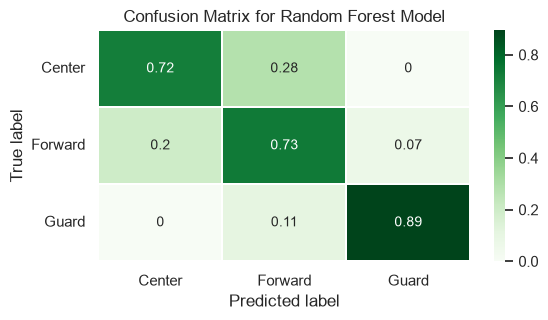

In [13]:
name_map = {'G': 'Guard', 'F': 'Forward', 'C': 'Center'} # to correctly label the classes in the figures

# get and reshape confusion matrix data
rf_confusion_matrix = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)
rf_confusion_matrix = rf_confusion_matrix.astype('float') / rf_confusion_matrix.sum(axis=1)[:, np.newaxis]

# make the heatmap
plt.figure(figsize=(6,3))
sns.set(font_scale=1)
sns.heatmap(rf_confusion_matrix, annot=True, annot_kws={'size':10}, cmap=plt.cm.Greens, linewidths=0.2)

# add labels
labels = [name_map[c] for c in rf_model.classes_]
tick_marks = np.arange(len(labels)) + 0.5
tick_marks2 = tick_marks
plt.xticks(tick_marks, labels, rotation=0)
plt.yticks(tick_marks2, labels, rotation=0)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix for Random Forest Model')
# plt.savefig("visualizations/rf_confusion_matrix")
plt.show()

#### Classification Report

In [14]:
rf_report = classification_report(y_test, y_pred_rf, output_dict=True)
rf_report_df = pd.DataFrame(rf_report).transpose().round(3)
rf_report_df.to_csv("visualizations/rf_classification_report.csv")
rf_report_df

,precision,recall,f1-score,support
C,0.667,0.718,0.691,39.000
F,0.732,0.732,0.732,71.000
G,0.932,0.895,0.913,76.000
accuracy,0.796,0.796,0.796,0.796
macro avg,0.777,0.782,0.779,186.000
weighted avg,0.800,0.796,0.797,186.000


What's especially noteworthy is that the test macro F1 (0.779) is close to the cross-validation macro F1 (0.787), suggesting that the model generalizes well.

#### Feature Importances

Next, let's see how much each feature contributed in the classification.

In [15]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns, name="importance")
importances = importances.sort_values(ascending=False)

importances_df = importances.reset_index().rename(columns={"index": "feature"}).round(3)
importances_df.to_csv("visualizations/rf_feature_importances.csv", index=False)
importances_df

,feature,importance
0,TR,0.319
1,3PAr,0.265
2,AST,0.172
3,BLK,0.100
4,2P,0.056
5,2Pr,0.038
6,AST/TO,0.033
7,FTr,0.013
8,3Pr,0.005


### Multinomial Logistic Regression

What logistic regression gives us that random forest doesn't is signed coefficients that tell us detailed information about the interactions between features and labels.

#### Coefficients

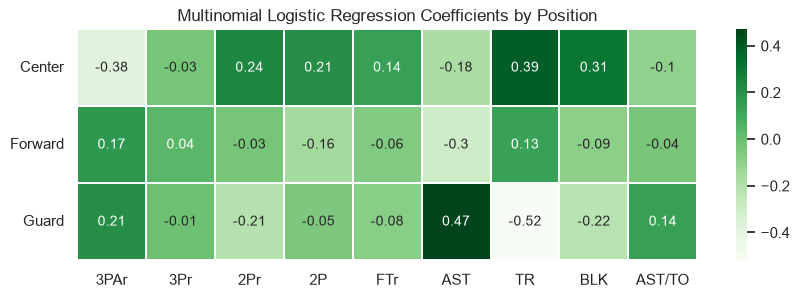

In [16]:
lr_model = lr_grid.best_estimator_.named_steps["clf"]
coef_df = pd.DataFrame(lr_model.coef_, columns=X_train.columns, index=lr_model.classes_).round(2)

plt.figure(figsize=(10,3))
sns.set(font_scale=1)
sns.heatmap(coef_df, annot=True, annot_kws={'size':10}, cmap=plt.cm.Greens, linewidths=0.2)

# add labels
labels = [name_map[c] for c in coef_df.index]
tick_marks2 = tick_marks
plt.yticks(tick_marks2, labels, rotation=0)
plt.title("Multinomial Logistic Regression Coefficients by Position")
# plt.savefig("visualizations/rf_coefficients")
plt.show()

#### Confusion Matrix

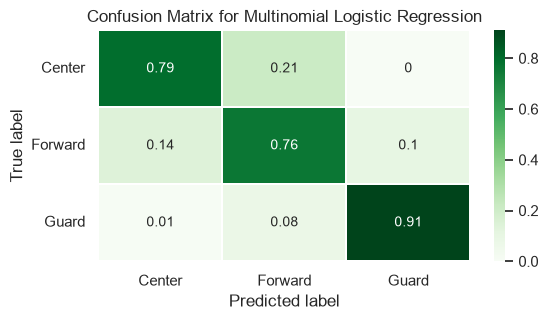

In [17]:
# get and reshape confusion matrix data
lr_confusion_matrix = confusion_matrix(y_test, y_pred_lr, labels=lr_model.classes_)
lr_confusion_matrix = lr_confusion_matrix.astype('float') / lr_confusion_matrix.sum(axis=1)[:, np.newaxis]

# make the heatmap
plt.figure(figsize=(6,3))
sns.set(font_scale=1)
sns.heatmap(lr_confusion_matrix.round(2), annot=True, annot_kws={'size':10}, cmap=plt.cm.Greens, linewidths=0.2)

# add labels
labels = [name_map[c] for c in lr_model.classes_]
tick_marks = np.arange(len(labels)) + 0.5
tick_marks2 = tick_marks
plt.xticks(tick_marks, labels, rotation=0)
plt.yticks(tick_marks2, labels, rotation=0)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix for Multinomial Logistic Regression')
# plt.savefig("visualizations/lr_confusion_matrix")
plt.show()

#### Classification Report

In [18]:
lr_report = classification_report(y_test, y_pred_lr, output_dict=True)
lr_report_df = pd.DataFrame(lr_report).transpose().round(3)
lr_report_df.to_csv("visualizations/lr_classification_report.csv")
lr_report_df

,precision,recall,f1-score,support
C,0.738,0.795,0.765,39.000
F,0.794,0.761,0.777,71.000
G,0.908,0.908,0.908,76.000
accuracy,0.828,0.828,0.828,0.828
macro avg,0.813,0.821,0.817,186.000
weighted avg,0.829,0.828,0.828,186.000


For logarithmic regression, test macro F1 (0.817) is actually *higher* than cross-validation macro F1 (0.792).